# Digit Recognizer with PyTorch

**Author:** Estelle Arnander · **Kaggle username:** estellearnander03

**Objective:** classify 28 x 28 grayscale handwritten digits (0 to 9) from the Kaggle Digit Recognizer competition.
We train an MLP baseline, a convolutional neural network (CNN) and improved CNNs, compare them on a hold-out
validation set and submit the best predictions to Kaggle.

All reusable code lives in the `digit_recognizer` package (`src/digit_recognizer/`). This notebook only imports it,
runs the experiments and shows the results.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from digit_recognizer import (
    DigitDataset,
    check_data,
    compute_mean_std,
    get_device,
    load_test,
    load_train,
    make_loaders,
    set_seed,
    split_train_val,
)

SEED = 42
set_seed(SEED)
device = get_device()
print("Device:", device)

Device: mps


## 1. Data

### 1.1 Paths

The project root is the folder that contains `pyproject.toml`. Depending on the editor, the notebook runs either
from `notebooks/` or from the project root, so we check both.

In [2]:
if (Path.cwd() / "pyproject.toml").exists():
    project_root = Path.cwd()
else:
    project_root = Path.cwd().parents[0]

data_dir = project_root / "data"
results_dir = project_root / "results"
results_dir.mkdir(exist_ok=True)
print("Project root:", project_root)

Project root: /Users/estellearnander/sem5/AI/digit-recognizer


### 1.2 Load and check the data

`check_data` confirms the expected shapes (42,000 x 785 and 28,000 x 784), that `label` is the first column,
that labels are 0 to 9, that pixels are 0 to 255 and that there are no missing values.

In [3]:
train_df = load_train(data_dir / "train.csv")
test_df = load_test(data_dir / "test.csv")

print("train.csv:", train_df.shape)
print("test.csv: ", test_df.shape)
print("Checks passed:", check_data(train_df, test_df))
train_df.iloc[:5, :8]

train.csv: (42000, 785)
test.csv:  (28000, 784)
Checks passed: True


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6
0,1,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0


### 1.3 Train / validation split and normalisation

We keep a stratified 90/10 hold-out split with a fixed seed, so every model is evaluated on exactly the same
4,200 validation images and each class keeps the same proportion in both parts.

Pixels are scaled to [0, 1] and then normalised with the mean and standard deviation of the **training split only**.
Computing them on all the data would let validation information leak into preprocessing.

In [4]:
X_train, X_val, y_train, y_val = split_train_val(train_df, val_size=0.1, seed=SEED)
mean, std = compute_mean_std(X_train)

print("Training images:  ", X_train.shape[0])
print("Validation images:", X_val.shape[0])
print(f"Training mean = {mean:.4f}, std = {std:.4f}")

Training images:   37800
Validation images: 4200
Training mean = 0.1310, std = 0.3085


### 1.4 Dataset and DataLoader

`DigitDataset` reshapes each row of 784 pixels to an image of shape `[1, 28, 28]` (1 channel, height, width).
The DataLoader groups images into batches of shape `[B, 1, 28, 28]`, the format a PyTorch CNN expects.

In [5]:
train_ds = DigitDataset(X_train, y_train, mean, std)
val_ds = DigitDataset(X_val, y_val, mean, std)
train_loader, val_loader = make_loaders(train_ds, val_ds, batch_size=128, seed=SEED)

images, labels = next(iter(train_loader))
print("Image batch:", tuple(images.shape), images.dtype)
print("Label batch:", tuple(labels.shape), labels.dtype)
print(f"Pixel values after normalisation: min {images.min():.2f}, max {images.max():.2f}")

Image batch: (128, 1, 28, 28) torch.float32
Label batch: (128,) torch.int64
Pixel values after normalisation: min -0.42, max 2.82


### 1.5 Look at the data

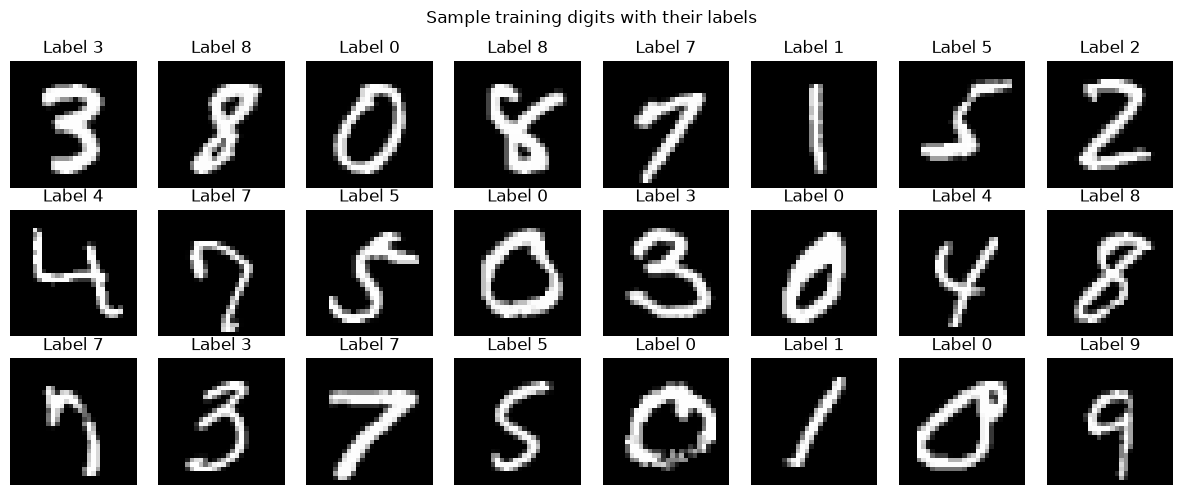

In [6]:
fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for ax, i in zip(axes.flat, range(24)):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Label {y_train[i]}")
    ax.axis("off")
fig.suptitle("Sample training digits with their labels")
plt.tight_layout()
plt.savefig(results_dir / "sample_digits.png", dpi=150, bbox_inches="tight")
plt.show()

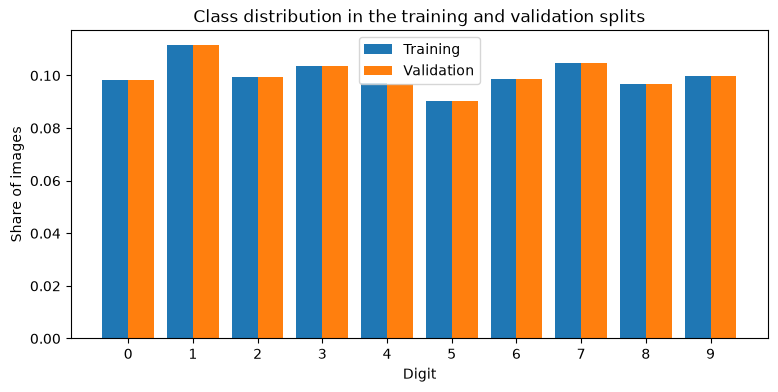

Training counts:   [3719 4216 3759 3916 3665 3415 3723 3961 3657 3769]
Validation counts: [413 468 418 435 407 380 414 440 406 419]


In [7]:
classes = np.arange(10)
train_counts = np.bincount(y_train, minlength=10)
val_counts = np.bincount(y_val, minlength=10)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(classes - 0.2, train_counts / train_counts.sum(), width=0.4, label="Training")
ax.bar(classes + 0.2, val_counts / val_counts.sum(), width=0.4, label="Validation")
ax.set_xticks(classes)
ax.set_xlabel("Digit")
ax.set_ylabel("Share of images")
ax.set_title("Class distribution in the training and validation splits")
ax.legend()
plt.savefig(results_dir / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("Training counts:  ", train_counts)
print("Validation counts:", val_counts)

**Observations**

- Stratification works: every digit has the same share of images in the training and validation splits.
- The classes are roughly balanced. The most common digit (1, with 4,216 training images) appears about
  1.2 times as often as the least common (5, with 3,415). With an imbalance this mild, accuracy is a fair
  metric (it is also the Kaggle metric) and no class weighting is needed in the loss.
- After normalisation the black background has the value -0.42 and the brightest strokes 2.82.

## 2. MLP baseline

The baseline is a multilayer perceptron: the 28 x 28 image is flattened into a vector of 784 pixels and passed
through two fully connected hidden layers (256 and 128 neurons, ReLU, dropout 0.2) to 10 output logits.

Flattening throws away the spatial layout of the image: the MLP does not know which pixels are neighbours, so it
has to learn every spatial pattern from scratch. This is the weakness the CNN in section 3 addresses with its
built-in assumptions of locality and translation invariance (lecture 8).

All models in this notebook use the same training setup so their results are comparable: Adam with learning rate
0.001, cross-entropy loss on the logits, batch size 128 and 15 epochs. After training, each model keeps the weights
of the epoch with the best validation accuracy.

In [8]:
from digit_recognizer import MLP, count_parameters, fit, plot_history

EPOCHS = 15
results = {}

set_seed(SEED)
mlp = MLP(hidden_dims=(256, 128), dropout=0.2)
print(mlp)
print("Trainable parameters:", count_parameters(mlp))

logits = mlp(images[:4])
print("Output shape for 4 images:", tuple(logits.shape))

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.2, inplace=False)
    (7): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 235146
Output shape for 4 images: (4, 10)


In [9]:
set_seed(SEED)
mlp_history = fit(mlp, train_loader, val_loader, epochs=EPOCHS, device=device, lr=1e-3)
results["MLP"] = {"history": mlp_history, "params": count_parameters(mlp)}

Epoch  1/15 | train loss 0.3888 acc 0.8802 | val loss 0.1705 acc 0.9498
Epoch  2/15 | train loss 0.1665 acc 0.9499 | val loss 0.1224 acc 0.9638
Epoch  3/15 | train loss 0.1197 acc 0.9635 | val loss 0.1027 acc 0.9693
Epoch  4/15 | train loss 0.0941 acc 0.9715 | val loss 0.0881 acc 0.9750
Epoch  5/15 | train loss 0.0795 acc 0.9751 | val loss 0.0939 acc 0.9726
Epoch  6/15 | train loss 0.0687 acc 0.9784 | val loss 0.0844 acc 0.9745
Epoch  7/15 | train loss 0.0616 acc 0.9800 | val loss 0.0812 acc 0.9755
Epoch  8/15 | train loss 0.0524 acc 0.9828 | val loss 0.0788 acc 0.9769
Epoch  9/15 | train loss 0.0459 acc 0.9850 | val loss 0.0783 acc 0.9788
Epoch 10/15 | train loss 0.0440 acc 0.9859 | val loss 0.0930 acc 0.9740
Epoch 11/15 | train loss 0.0454 acc 0.9849 | val loss 0.0775 acc 0.9779
Epoch 12/15 | train loss 0.0347 acc 0.9888 | val loss 0.0836 acc 0.9776
Epoch 13/15 | train loss 0.0319 acc 0.9896 | val loss 0.0891 acc 0.9767
Epoch 14/15 | train loss 0.0337 acc 0.9886 | val loss 0.0892 acc

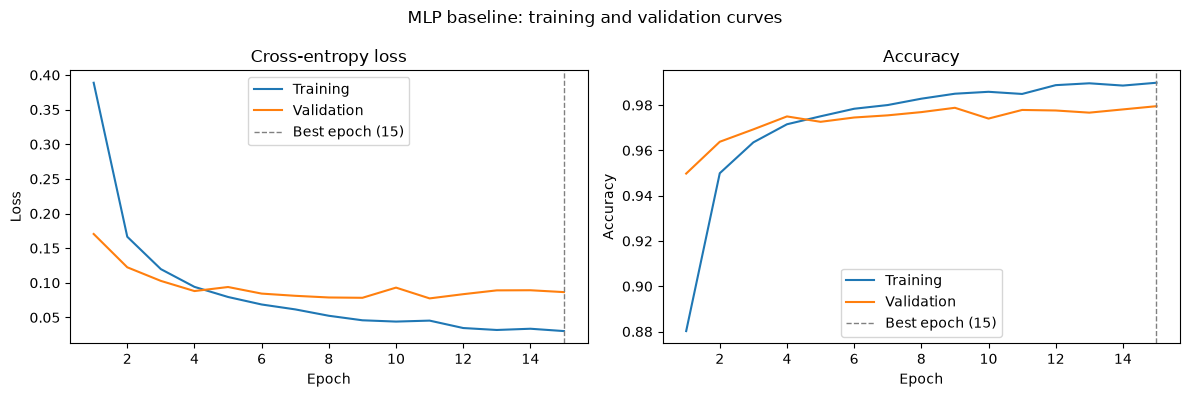

MLP best validation accuracy: 0.9795 (epoch 15)


In [10]:
plot_history(mlp_history, "MLP baseline: training and validation curves",
             save_path=results_dir / "mlp_curves.png")
print(f"MLP best validation accuracy: {mlp_history['best_val_acc']:.4f} (epoch {mlp_history['best_epoch']})")

**Observations**

- The MLP reaches **0.9795** validation accuracy, above the 0.97 reference for a simple MLP given in the brief.
- Overfitting starts around epoch 11: validation loss is lowest there (0.0775) and then rises, while training loss
  keeps falling. The network begins to memorise training images instead of learning patterns that generalise.
- Validation loss and accuracy disagree on the best epoch (11 for loss, 15 for accuracy). Accuracy only counts right
  or wrong answers, while loss also penalises low confidence. We select on accuracy because it is the Kaggle metric.
- Validation accuracy moves by about ±0.3 points from one epoch to the next. With 4,200 validation images at about
  98% accuracy, the standard error is about 0.2 points, so differences between models smaller than about 0.3 to 0.4
  points should not be treated as real.

## 3. Convolutional neural network

The CNN keeps the image as a 28 x 28 grid. Each convolution slides small 3 x 3 filters over the image, so it looks
at neighbouring pixels together (locality) and reuses the same filter at every position (translation invariance).
These built-in assumptions (the inductive bias from lecture 8) mean the network does not have to learn spatial
structure from scratch, which an MLP has to do.

Architecture, two convolutional blocks, no regularisation:

| Layer | Output shape |
|---|---|
| Input | [B, 1, 28, 28] |
| Conv 3x3, 32 filters, padding 1 → ReLU → MaxPool 2 | [B, 32, 14, 14] |
| Conv 3x3, 64 filters, padding 1 → ReLU → MaxPool 2 | [B, 64, 7, 7] |
| Flatten → Linear 128 → ReLU | [B, 128] |
| Linear | [B, 10] logits |

Padding 1 keeps height and width unchanged after each 3 x 3 convolution; each max pooling halves them.
The training setup is identical to the MLP's.

In [11]:
from digit_recognizer import SimpleCNN

set_seed(SEED)
cnn = SimpleCNN()

x = images[:4].cpu()
print(f"{'Input':45s} {tuple(x.shape)}")
for layer in list(cnn.features) + list(cnn.classifier):
    x = layer(x)
    print(f"{str(layer):45.45s} {tuple(x.shape)}")

Input                                         (4, 1, 28, 28)
Conv2d(1, 32, kernel_size=(3, 3), stride=(1,  (4, 32, 28, 28)
ReLU()                                        (4, 32, 28, 28)
MaxPool2d(kernel_size=2, stride=2, padding=0, (4, 32, 14, 14)
Conv2d(32, 64, kernel_size=(3, 3), stride=(1, (4, 64, 14, 14)
ReLU()                                        (4, 64, 14, 14)
MaxPool2d(kernel_size=2, stride=2, padding=0, (4, 64, 7, 7)
Flatten(start_dim=1, end_dim=-1)              (4, 3136)
Linear(in_features=3136, out_features=128, bi (4, 128)
ReLU()                                        (4, 128)
Linear(in_features=128, out_features=10, bias (4, 10)


In [12]:
for name, model in [("MLP", mlp), ("SimpleCNN", cnn)]:
    print(f"{name:10s} {count_parameters(model):>9,} trainable parameters")

first_linear = cnn.classifier[1]
print(f"Of which in the CNN's first linear layer: {count_parameters(first_linear):,}")

MLP          235,146 trainable parameters
SimpleCNN    421,642 trainable parameters
Of which in the CNN's first linear layer: 401,536


In [13]:
set_seed(SEED)
cnn_history = fit(cnn, train_loader, val_loader, epochs=EPOCHS, device=device, lr=1e-3)
results["SimpleCNN"] = {"history": cnn_history, "params": count_parameters(cnn)}

Epoch  1/15 | train loss 0.2208 acc 0.9328 | val loss 0.0652 acc 0.9807
Epoch  2/15 | train loss 0.0558 acc 0.9830 | val loss 0.0462 acc 0.9871
Epoch  3/15 | train loss 0.0362 acc 0.9886 | val loss 0.0478 acc 0.9867
Epoch  4/15 | train loss 0.0272 acc 0.9914 | val loss 0.0460 acc 0.9855
Epoch  5/15 | train loss 0.0238 acc 0.9919 | val loss 0.0411 acc 0.9898
Epoch  6/15 | train loss 0.0156 acc 0.9951 | val loss 0.0556 acc 0.9871
Epoch  7/15 | train loss 0.0130 acc 0.9957 | val loss 0.0633 acc 0.9833
Epoch  8/15 | train loss 0.0109 acc 0.9965 | val loss 0.0498 acc 0.9879
Epoch  9/15 | train loss 0.0072 acc 0.9978 | val loss 0.0516 acc 0.9888
Epoch 10/15 | train loss 0.0071 acc 0.9978 | val loss 0.0491 acc 0.9898
Epoch 11/15 | train loss 0.0065 acc 0.9976 | val loss 0.0632 acc 0.9855
Epoch 12/15 | train loss 0.0067 acc 0.9974 | val loss 0.0610 acc 0.9876
Epoch 13/15 | train loss 0.0067 acc 0.9977 | val loss 0.0696 acc 0.9867
Epoch 14/15 | train loss 0.0061 acc 0.9979 | val loss 0.0654 acc

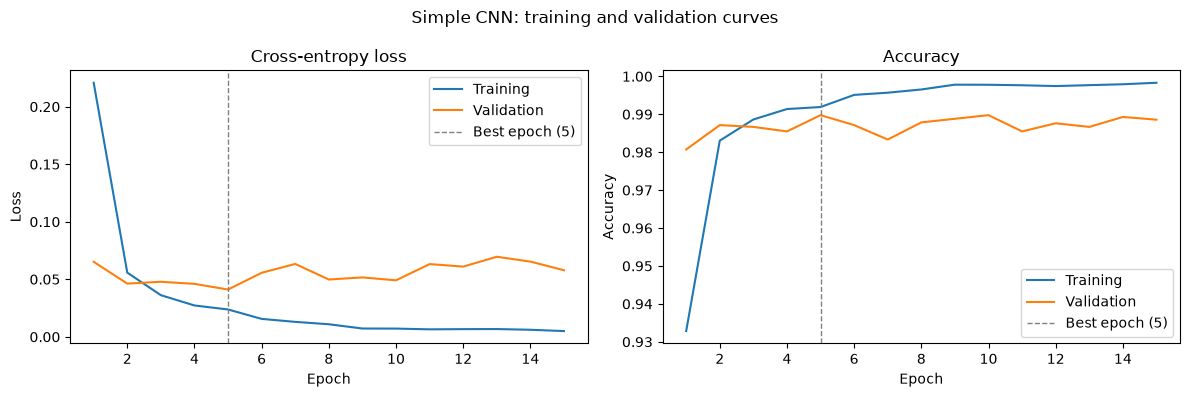

SimpleCNN best validation accuracy: 0.9898 (epoch 5)
MLP best validation accuracy:       0.9795 (epoch 15)


In [14]:
plot_history(cnn_history, "Simple CNN: training and validation curves",
             save_path=results_dir / "simple_cnn_curves.png")
print(f"SimpleCNN best validation accuracy: {cnn_history['best_val_acc']:.4f} (epoch {cnn_history['best_epoch']})")
print(f"MLP best validation accuracy:       {mlp_history['best_val_acc']:.4f} (epoch {mlp_history['best_epoch']})")

**Observations**

- The CNN reaches **0.9898** validation accuracy at epoch 5, 1.03 points above the MLP. That is well beyond the
  ±0.3 to 0.4 point noise band. In errors: the MLP misclassifies about 86 of the 4,200 validation images, the CNN
  about 43, so the CNN halves the error.
- Re-running the notebook after a kernel restart gave exactly the same MLP results in every epoch, so the fixed
  seeds make the training reproducible on this machine.
- The CNN overfits strongly: training accuracy reaches 0.998 while validation loss is lowest at epoch 5 (0.0411) and
  then rises to 0.06 to 0.07. Most of the 15 epochs are spent memorising the training images.
- The CNN has more parameters than the MLP (421,642 against 235,146), and 401,536 of them are in its first linear
  layer. So the comparison alone does not prove that convolutions, rather than size, explain the gain. Section 4.1
  tests this directly.

## 4. Improvements

Two questions:

1. **Is the CNN better only because it is bigger?** A control model answers this (4.1).
2. **Can regularisation reduce the CNN's overfitting?** An ablation answers this (4.2 to 4.4): each model changes
   exactly one thing from the previous one, so the effect of each change can be measured separately.

| Model | Change from the previous row | Epochs |
|---|---|---|
| SimpleCNN | (reference from section 3) | 15 |
| B: ImprovedCNN | + BatchNorm after each convolution, dropout 0.25 after each block and 0.5 in the head | 30 |
| C: ImprovedCNN + augmentation | + random rotations, shifts and zooms of the training images | 30 |
| D: C + cosine schedule | + learning rate decreasing from 0.001 towards 0 | 30 |

B, C and D all get 30 epochs. Augmentation makes each epoch harder, so it needs more epochs; giving B the same
number keeps training length out of the comparison. Because `fit` keeps the best epoch, extra epochs cannot hurt B.

### 4.1 Control: is it the size?

`SimpleCNNGAP` has the same two convolutional blocks as `SimpleCNN`, but replaces the large flatten-and-linear head
with global average pooling: each of the 64 feature maps is averaged to a single number, followed by one
Linear(64 → 10). This removes about 95% of the parameters, leaving fewer than the MLP has.

In [15]:
from digit_recognizer import ImprovedCNN, SimpleCNNGAP, make_augmentation

EPOCHS_REG = 30

set_seed(SEED)
cnn_gap = SimpleCNNGAP()
print("SimpleCNNGAP trainable parameters:", count_parameters(cnn_gap))

set_seed(SEED)
gap_history = fit(cnn_gap, train_loader, val_loader, epochs=EPOCHS, device=device, lr=1e-3)
results["SimpleCNN-GAP (control)"] = {"history": gap_history, "params": count_parameters(cnn_gap)}

SimpleCNNGAP trainable parameters: 19466
Epoch  1/15 | train loss 1.7088 acc 0.4000 | val loss 1.2678 acc 0.5681
Epoch  2/15 | train loss 1.0247 acc 0.7003 | val loss 0.8204 acc 0.7488
Epoch  3/15 | train loss 0.6989 acc 0.8054 | val loss 0.6195 acc 0.8174
Epoch  4/15 | train loss 0.5164 acc 0.8571 | val loss 0.4548 acc 0.8786
Epoch  5/15 | train loss 0.4138 acc 0.8861 | val loss 0.3858 acc 0.8905
Epoch  6/15 | train loss 0.3507 acc 0.9024 | val loss 0.3266 acc 0.9095
Epoch  7/15 | train loss 0.3117 acc 0.9116 | val loss 0.2918 acc 0.9164
Epoch  8/15 | train loss 0.2794 acc 0.9205 | val loss 0.2665 acc 0.9217
Epoch  9/15 | train loss 0.2602 acc 0.9245 | val loss 0.2483 acc 0.9281
Epoch 10/15 | train loss 0.2389 acc 0.9310 | val loss 0.2249 acc 0.9333
Epoch 11/15 | train loss 0.2254 acc 0.9349 | val loss 0.2162 acc 0.9376
Epoch 12/15 | train loss 0.2127 acc 0.9384 | val loss 0.2089 acc 0.9352
Epoch 13/15 | train loss 0.2044 acc 0.9407 | val loss 0.1946 acc 0.9414
Epoch 14/15 | train los

### 4.2 Model B: BatchNorm and dropout

BatchNorm normalises the output of each convolution over the batch, which stabilises training and has a mild
regularising effect (lecture 7). Dropout switches off a random fraction of activations at every training step, so
the network cannot rely on any single neuron (lecture 5). Both behave differently in training and evaluation, which
is why `fit` switches between `model.train()` and `model.eval()`.

In [16]:
set_seed(SEED)
model_b = ImprovedCNN(conv_dropout=0.25, head_dropout=0.5)
print("ImprovedCNN trainable parameters:", count_parameters(model_b))

set_seed(SEED)
b_history = fit(model_b, train_loader, val_loader, epochs=EPOCHS_REG, device=device, lr=1e-3)
results["B: + BatchNorm + dropout"] = {"history": b_history, "params": count_parameters(model_b)}

ImprovedCNN trainable parameters: 421738
Epoch  1/30 | train loss 0.3866 acc 0.8792 | val loss 0.0802 acc 0.9771
Epoch  2/30 | train loss 0.1446 acc 0.9561 | val loss 0.0602 acc 0.9812
Epoch  3/30 | train loss 0.1150 acc 0.9649 | val loss 0.0569 acc 0.9840
Epoch  4/30 | train loss 0.1002 acc 0.9690 | val loss 0.0469 acc 0.9857
Epoch  5/30 | train loss 0.0898 acc 0.9721 | val loss 0.0432 acc 0.9876
Epoch  6/30 | train loss 0.0823 acc 0.9754 | val loss 0.0392 acc 0.9886
Epoch  7/30 | train loss 0.0740 acc 0.9771 | val loss 0.0403 acc 0.9888
Epoch  8/30 | train loss 0.0732 acc 0.9770 | val loss 0.0444 acc 0.9886
Epoch  9/30 | train loss 0.0678 acc 0.9787 | val loss 0.0409 acc 0.9883
Epoch 10/30 | train loss 0.0663 acc 0.9788 | val loss 0.0418 acc 0.9874
Epoch 11/30 | train loss 0.0637 acc 0.9798 | val loss 0.0382 acc 0.9907
Epoch 12/30 | train loss 0.0551 acc 0.9822 | val loss 0.0389 acc 0.9907
Epoch 13/30 | train loss 0.0550 acc 0.9824 | val loss 0.0345 acc 0.9902
Epoch 14/30 | train los

### 4.3 Model C: data augmentation

Every time a training image is used, it is randomly rotated by up to ±10°, shifted by up to 10% and zoomed between
90% and 110%. The network never sees exactly the same image twice, which makes memorising harder. These changes
mimic how people actually write digits differently.

No flips are used: a mirrored digit is no longer the same digit. Rotations are kept small because a large rotation
could turn a 6 into a 9. Validation images are never augmented, so the validation score stays comparable.

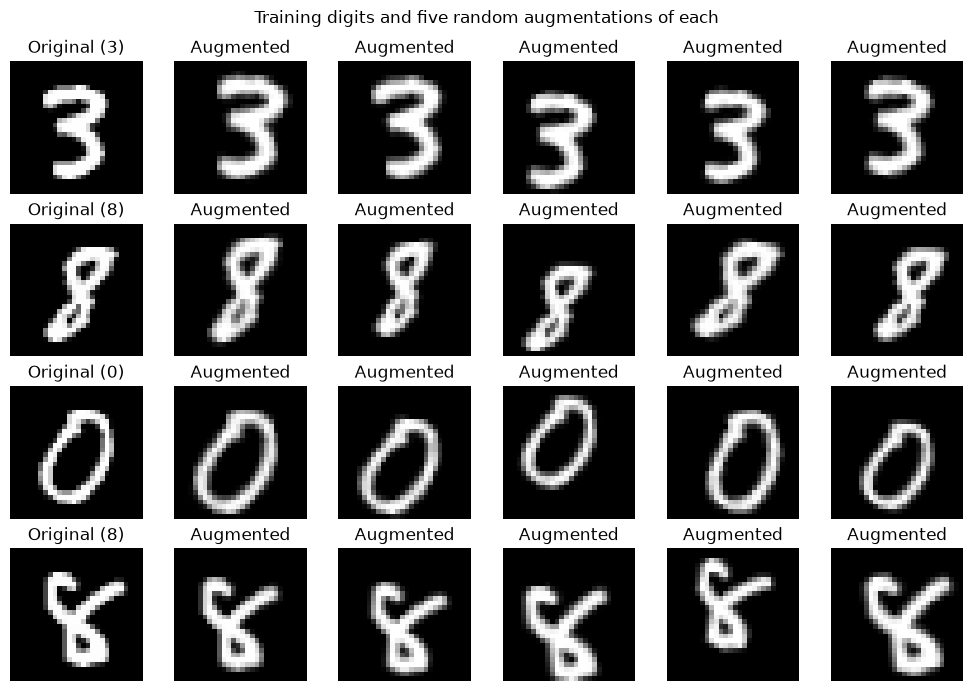

In [17]:
augment = make_augmentation(degrees=10, shift=0.1, scale=(0.9, 1.1))
display_ds = DigitDataset(X_train, y_train, mean=0.0, std=1.0, transform=augment)

set_seed(SEED)
fig, axes = plt.subplots(4, 6, figsize=(10, 7))
for row, idx in enumerate([0, 1, 2, 3]):
    axes[row, 0].imshow(X_train[idx].reshape(28, 28), cmap="gray")
    axes[row, 0].set_title(f"Original ({y_train[idx]})")
    for col in range(1, 6):
        augmented, _ = display_ds[idx]
        axes[row, col].imshow(augmented.squeeze(0), cmap="gray")
        axes[row, col].set_title("Augmented")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Training digits and five random augmentations of each")
plt.tight_layout()
plt.savefig(results_dir / "augmentation_examples.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
train_aug_ds = DigitDataset(X_train, y_train, mean, std, transform=augment)
train_aug_loader, _ = make_loaders(train_aug_ds, val_ds, batch_size=128, seed=SEED)

set_seed(SEED)
model_c = ImprovedCNN(conv_dropout=0.25, head_dropout=0.5)
set_seed(SEED)
c_history = fit(model_c, train_aug_loader, val_loader, epochs=EPOCHS_REG, device=device, lr=1e-3)
results["C: B + augmentation"] = {"history": c_history, "params": count_parameters(model_c)}

Epoch  1/30 | train loss 0.7567 acc 0.7513 | val loss 0.1147 acc 0.9636
Epoch  2/30 | train loss 0.3503 acc 0.8907 | val loss 0.0623 acc 0.9802
Epoch  3/30 | train loss 0.2863 acc 0.9114 | val loss 0.0679 acc 0.9781
Epoch  4/30 | train loss 0.2490 acc 0.9217 | val loss 0.0502 acc 0.9864
Epoch  5/30 | train loss 0.2224 acc 0.9312 | val loss 0.0473 acc 0.9852
Epoch  6/30 | train loss 0.2161 acc 0.9337 | val loss 0.0439 acc 0.9871
Epoch  7/30 | train loss 0.1979 acc 0.9373 | val loss 0.0391 acc 0.9871
Epoch  8/30 | train loss 0.1836 acc 0.9429 | val loss 0.0375 acc 0.9890
Epoch  9/30 | train loss 0.1763 acc 0.9459 | val loss 0.0403 acc 0.9881
Epoch 10/30 | train loss 0.1759 acc 0.9474 | val loss 0.0366 acc 0.9888
Epoch 11/30 | train loss 0.1613 acc 0.9507 | val loss 0.0368 acc 0.9881
Epoch 12/30 | train loss 0.1588 acc 0.9525 | val loss 0.0299 acc 0.9912
Epoch 13/30 | train loss 0.1462 acc 0.9557 | val loss 0.0264 acc 0.9917
Epoch 14/30 | train loss 0.1498 acc 0.9545 | val loss 0.0278 acc

### 4.4 Model D: learning-rate schedule

A cosine schedule lowers the learning rate smoothly from 0.001 towards 0 over the 30 epochs (the scheduler used
in the Session 12 notebook). Large steps early on make fast progress; small steps at the end let the weights settle
into a minimum instead of bouncing around it.

In [19]:
set_seed(SEED)
model_d = ImprovedCNN(conv_dropout=0.25, head_dropout=0.5)
set_seed(SEED)
d_history = fit(model_d, train_aug_loader, val_loader, epochs=EPOCHS_REG, device=device, lr=1e-3, scheduler="cosine")
results["D: C + cosine schedule"] = {"history": d_history, "params": count_parameters(model_d)}

Epoch  1/30 | train loss 0.7978 acc 0.7346 | val loss 0.1085 acc 0.9660
Epoch  2/30 | train loss 0.3779 acc 0.8813 | val loss 0.0742 acc 0.9755
Epoch  3/30 | train loss 0.3216 acc 0.9002 | val loss 0.0691 acc 0.9774
Epoch  4/30 | train loss 0.2847 acc 0.9116 | val loss 0.0483 acc 0.9855
Epoch  5/30 | train loss 0.2523 acc 0.9222 | val loss 0.0491 acc 0.9855
Epoch  6/30 | train loss 0.2351 acc 0.9280 | val loss 0.0443 acc 0.9869
Epoch  7/30 | train loss 0.2209 acc 0.9327 | val loss 0.0518 acc 0.9850
Epoch  8/30 | train loss 0.2010 acc 0.9382 | val loss 0.0412 acc 0.9886
Epoch  9/30 | train loss 0.1958 acc 0.9401 | val loss 0.0407 acc 0.9871
Epoch 10/30 | train loss 0.1938 acc 0.9412 | val loss 0.0386 acc 0.9876
Epoch 11/30 | train loss 0.1762 acc 0.9455 | val loss 0.0418 acc 0.9879
Epoch 12/30 | train loss 0.1718 acc 0.9475 | val loss 0.0372 acc 0.9895
Epoch 13/30 | train loss 0.1653 acc 0.9498 | val loss 0.0340 acc 0.9902
Epoch 14/30 | train loss 0.1592 acc 0.9506 | val loss 0.0373 acc

### 4.5 Comparison

In [20]:
import pandas as pd

n_val = len(y_val)
rows = []
for name, res in results.items():
    h = res["history"]
    rows.append({
        "Model": name,
        "Parameters": res["params"],
        "Best val accuracy": round(h["best_val_acc"], 4),
        "Val errors (of 4,200)": round((1 - h["best_val_acc"]) * n_val),
        "Best epoch": h["best_epoch"],
        "Epochs trained": len(h["val_acc"]),
        "Training time (s)": round(h["train_time_s"]),
    })
comparison = pd.DataFrame(rows)
comparison.to_csv(results_dir / "model_comparison.csv", index=False)
comparison

,Model,Parameters,Best val accuracy,"Val errors (of 4,200)",Best epoch,Epochs trained,Training time (s)
0,MLP,235146,0.9795,86,15,15,18
1,SimpleCNN,421642,0.9898,43,5,15,82
2,SimpleCNN-GAP (control),19466,0.9414,246,13,15,72
3,B: + BatchNorm + dropout,421738,0.9929,30,28,30,155
4,C: B + augmentation,421738,0.9926,31,29,30,157
5,D: C + cosine schedule,421738,0.9931,29,29,30,160
